# Unidad 6: Modelos de ensamble

### FCEIA | Tec. Universitaria en Inteligencia Artificial | Minería de Datos


Los modelos de ensamble combinan las predicciones de varios modelos base para construir un predictor más estable y con mayor capacidad de generalización. En esta clase llevaremos a la práctica los métodos paralelos (**Bagging** y **Random Forest**).

La práctica tendrá dos partes:

1. Una demostración sobre un conjunto sintético.
2. Una aplicación sobre datos anonimizados de pólizas de motos.

## 🎯 Objetivos de aprendizaje

Al finalizar la actividad se espera que puedan:

- explicar por qué un ensamble puede superar a un árbol individual;
- relacionar los ensambles con el compromiso entre sesgo y varianza;
- diferenciar Bagging de Random Forest;
- interpretar una estimación *Out-Of-Bag*;
- evaluar clasificadores con más de una métrica.

# Librerías



In [ ]:
# MANIPULACIÓN DE DATOS
import numpy as np
import pandas as pd

# VISUALIZACIÓN
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

# MACHINE LEARNING

# GENERACIÓN Y DIVISIÓN DE DATOS
from sklearn.datasets import make_moons
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     cross_validate, GridSearchCV)

# MODELOS
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import (BaggingClassifier, RandomForestClassifier)

# MÉTRICAS
from sklearn.metrics import (accuracy_score, precision_score,
                             recall_score, f1_score)

# INTERPRETACIÓN
from sklearn.inspection import DecisionBoundaryDisplay

# CONFIGURACIÓN GENERAL
# Aplicamos un estilo visual homogéneo.
sns.set_theme(style="whitegrid")
# Utilizaremos la misma semilla en todo el notebook.
SEMILLA = 63

1. ¿Qué resultados podrían cambiar si no fijáramos una semilla?
2. ¿Por qué es conveniente utilizar la misma semilla al comparar modelos?

# 1. Conjunto de datos sintéticos

Utilizaremos `make_moons` para crear un conjunto sintético de clasificación binaria. Este conjunto resulta útil porque las clases presentan una frontera no lineal, por lo que un modelo lineal simple tendría dificultades para separarlas.

Agregaremos ruido para que la clasificación no sea perfecta y se parezca más a un problema real. Después dividiremos los datos en entrenamiento y prueba mediante una partición estratificada.

In [ ]:
# Generamos 400 observaciones distribuidas en dos clases.
X_moons, y_moons = make_moons(
    n_samples=400,
    noise=0.3,
    random_state=SEMILLA
)

# Separamos el 20 % de los datos para la evaluación final.
X_train_moons, X_test_moons, y_train_moons, y_test_moons = train_test_split(
    X_moons,
    y_moons,
    test_size=0.2,
    stratify=y_moons,
    random_state=SEMILLA
)

print("Dimensión del conjunto completo:", X_moons.shape)
print("Dimensión de entrenamiento:", X_train_moons.shape)
print("Dimensión de prueba:", X_test_moons.shape)

Dimensión del conjunto completo: (400, 2)
Dimensión de entrenamiento: (320, 2)
Dimensión de prueba: (80, 2)


In [ ]:
fig = px.scatter(x=X_moons[:, 0], y=X_moons[:, 1],
                 color=y_moons.astype(np.ubyte),
                 labels={'x': 'Característica 1', 'y': 'Característica 2'},
                 title="Conjunto sintético make_moons",
                 width=700, height=500)
fig.update_layout(legend_title_text='Clases')

1. ¿La separación entre las clases puede realizarse mediante una única línea recta?
2. ¿Qué observaciones parecen más difíciles de clasificar?

## 1.1 Repaso: árboles de decisión

Un árbol de decisión divide el espacio de características mediante reglas sucesivas. En clasificación, una de las medidas utilizadas para elegir una división es la impureza de Gini.

Un árbol profundo puede aprender fronteras muy complejas. Esto reduce el error de entrenamiento, pero puede aumentar la sensibilidad del modelo frente a pequeñas variaciones de los datos.

https://scikit-learn.org/dev/modules/generated/sklearn.tree.DecisionTreeClassifier.html

In [ ]:
# Creamos un árbol con profundidad limitada.
arbol_interpretable = DecisionTreeClassifier(max_depth=3, random_state=SEMILLA)
arbol_interpretable.fit(X_train_moons, y_train_moons)

# Predecimos las clases del conjunto de prueba.
predicciones_arbol_interpretable = arbol_interpretable.predict(X_test_moons)

# Calculamos la proporción de predicciones correctas.
accuracy_arbol_interpretable = accuracy_score(y_test_moons,
                                              predicciones_arbol_interpretable)

print(f"Accuracy del árbol: {accuracy_arbol_interpretable:.3f}")

Accuracy del árbol: 0.863


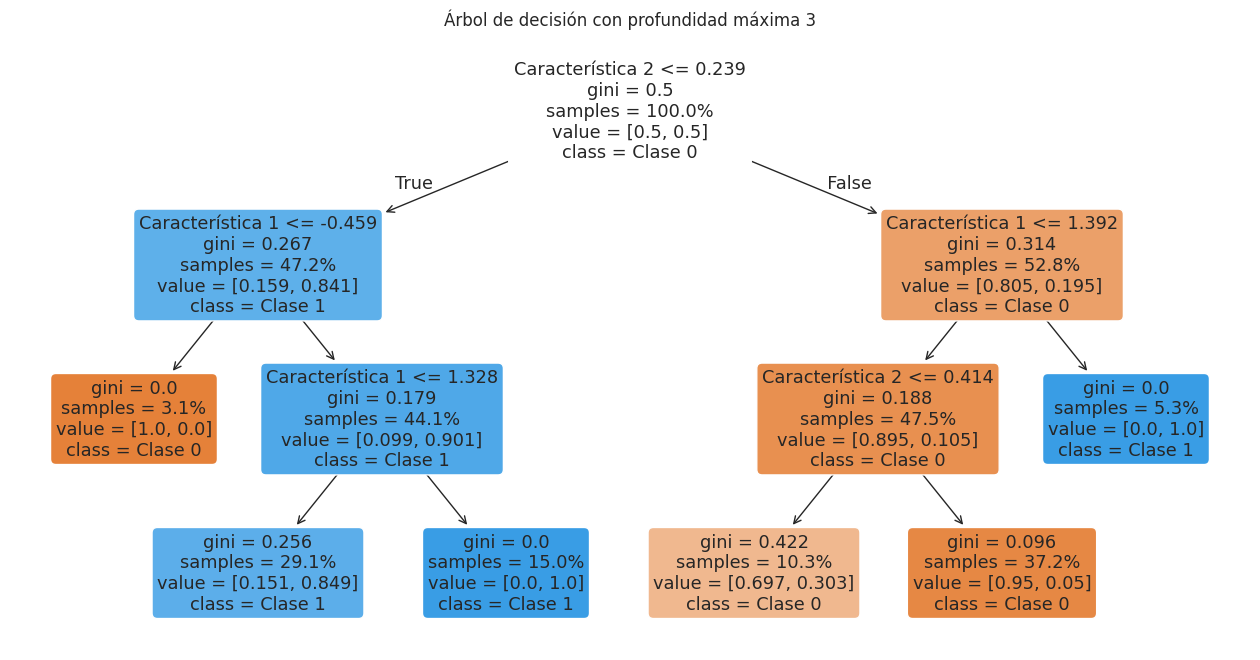

In [ ]:
# Definimos el tamaño de la figura.
plt.figure(figsize=(16, 8))

# Representamos las decisiones del árbol.
plot_tree(
    arbol_interpretable,
    feature_names=["Característica 1", "Característica 2"],
    class_names=["Clase 0", "Clase 1"],
    # Coloreamos los nodos según la clase predominante.
    filled=True, rounded=True,
    # Mostramos proporciones de las muestras.
    proportion=True
)

plt.title("Árbol de decisión con profundidad máxima 3")
plt.show()

1. ¿Qué variable se utiliza en la primera división?
2. ¿Qué efecto tendría aumentar considerablemente `max_depth`?

## 1.2 Sesgo, varianza y árboles profundos

El error esperado de un modelo puede analizarse mediante la descomposición de ruido, sesgo y varianza.

Un árbol profundo suele tener bajo sesgo porque puede representar relaciones complejas. Sin embargo, puede presentar alta varianza, ya que pequeños cambios en la muestra de entrenamiento pueden producir reglas diferentes.

In [ ]:
# Creamos un árbol sin limitar su profundidad.
arbol_profundo = DecisionTreeClassifier(random_state=SEMILLA)
arbol_profundo.fit(X_train_moons, y_train_moons)

# Predecimos y calculamos el desempeño.
predicciones_train_arbol = arbol_profundo.predict(X_train_moons)
predicciones_test_arbol = arbol_profundo.predict(X_test_moons)

# Calculamos el desempeño en prueba y entrenamiento
accuracy_train_arbol = accuracy_score(y_train_moons, predicciones_train_arbol)
accuracy_test_arbol = accuracy_score(y_test_moons, predicciones_test_arbol)

print(f"Accuracy de entrenamiento: {accuracy_train_arbol:.3f}")
print(f"Accuracy de prueba:        {accuracy_test_arbol:.3f}")
print(
    "Diferencia train-test:     "
    f"{accuracy_train_arbol - accuracy_test_arbol:.3f}"
)

Accuracy de entrenamiento: 1.000
Accuracy de prueba:        0.875
Diferencia train-test:     0.125


### Preguntas para analizar

1. ¿Qué indica una diferencia entre el desempeño entre entrenamiento y prueba?
2. ¿Por qué los árboles profundos son buenos candidatos para utilizar en Bagging?

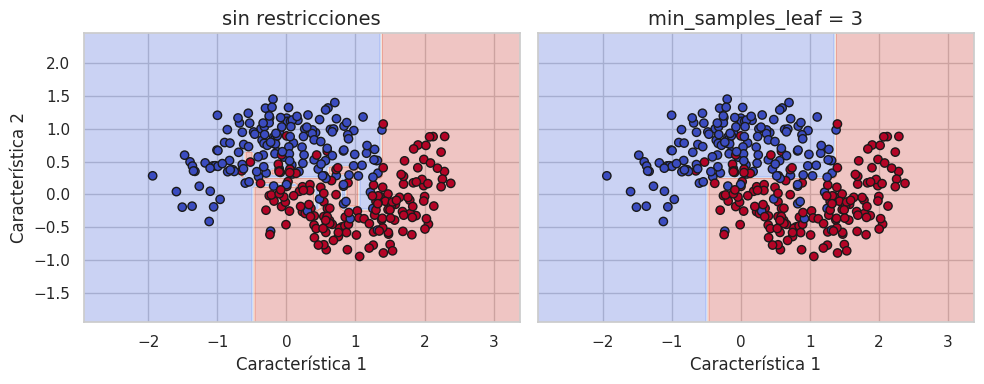

In [ ]:
# Gráfica de los límites de decisión usando sklearn
fig, axes = plt.subplots(ncols=2, figsize=(10, 4), sharey=True)

# Gráfico 1: Sin restricciones
DecisionBoundaryDisplay.from_estimator(
    arbol_profundo, X_train_moons, response_method="predict",
    ax=axes[0], alpha=0.3, cmap=plt.cm.coolwarm
)
axes[0].scatter(X_train_moons[:, 0], X_train_moons[:, 1], c=y_train_moons,
                edgecolor='k', cmap=plt.cm.coolwarm)
axes[0].set_title("sin restricciones", fontsize=14)
axes[0].set_xlabel("Característica 1")
axes[0].set_ylabel("Característica 2")

# Gráfico 2: Con maxdepth=3
DecisionBoundaryDisplay.from_estimator(
    arbol_interpretable, X_train_moons, response_method="predict",
    ax=axes[1], alpha=0.3, cmap=plt.cm.coolwarm
)
axes[1].scatter(X_train_moons[:, 0], X_train_moons[:, 1], c=y_train_moons,
                edgecolor='k', cmap=plt.cm.coolwarm)
axes[1].set_title(f"min_samples_leaf = {arbol_interpretable.max_depth}",
                  fontsize=14)
axes[1].set_xlabel("Característica 1")

plt.tight_layout()
plt.show()

## 1.3  Bagging con Bootstrap

Es un método estadístico en donde cada muestra es obtenida con reemplazo. Por este motivo, una observación puede aparecer varias veces y otras pueden quedar fuera de la muestra.

La probabilidad de que una observación no sea elegida tiende a 0.36%

Las observaciones que quedan afuera se denominan **Out-Of-Bag**.

Bagging entrena varios modelos de forma independiente sobre distintas muestras por bootstrap. En clasificación, las predicciones se combinan mediante voto mayoritario. Entonces, la combinación puede reducir la varianza cuando los modelos cometen errores diferentes.

In [ ]:
# Definimos el estimador que se repetirá dentro del ensamble.
estimador_base = DecisionTreeClassifier(random_state=SEMILLA)

# Creamos el ensamble.
modelo_bagging = BaggingClassifier(
    estimator=estimador_base, # Cada componente será un árbol de decisión.
    n_estimators=100, # Entrenaremos 100 árboles.
    bootstrap=True, # Cada árbol recibirá una muestra bootstrap.
    oob_score=True, # Solicitamos la evaluación OOB.
    n_jobs=-1,     # Utilizamos todos los núcleos disponibles.
    random_state=SEMILLA
)

modelo_bagging.fit(X_train_moons, y_train_moons)

# Calculamos predicciones y métricas.
predicciones_bagging = modelo_bagging.predict(X_test_moons)

accuracy_bagging = accuracy_score(y_test_moons, predicciones_bagging)

f1_bagging = f1_score(y_test_moons, predicciones_bagging)

print(f"Accuracy de Bagging: {accuracy_bagging:.3f}")
print(f"F1 de Bagging:       {f1_bagging:.3f}")
print(f"Accuracy OOB:         {modelo_bagging.oob_score_:.3f}")

Accuracy de Bagging: 0.887
F1 de Bagging:       0.889
Accuracy OOB:         0.866


In [ ]:
# Organizamos los resultados en una tabla.
comparacion_arbol_bagging = pd.DataFrame({
    "Modelo": [
        "Árbol profundo",
        "Bagging"
    ],
    "Accuracy de prueba": [
        accuracy_test_arbol,
        accuracy_bagging
    ],
    "F1 de prueba": [
        f1_score(y_test_moons, predicciones_test_arbol),
        f1_bagging
    ],
    "Accuracy OOB": [
        np.nan,
        modelo_bagging.oob_score_
    ]
})

display(
    comparacion_arbol_bagging.round(3)
)

,Modelo,Accuracy de prueba,F1 de prueba,Accuracy OOB
0,Árbol profundo,0.875,0.878,NaN
1,Bagging,0.888,0.889,0.866


## 1.4 Random Forest

En Bagging, todos los atributos pueden evaluarse en cada división. Si existe una variable dominante, los árboles pueden terminar siendo muy similares.

Random Forest agrega una segunda fuente de aleatoriedad: en cada nodo se evalúa solamente un subconjunto de atributos. En clasificación suele utilizarse:

$$
p \approx \sqrt{d}
$$

donde \(d\) es la cantidad total de características.

https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html

In [ ]:
modelo_random_forest = RandomForestClassifier(n_estimators=200,
    max_features="sqrt", # Elejimos la cantidad de atributos
    bootstrap=True, oob_score=True, n_jobs=-1, random_state=SEMILLA
)

modelo_random_forest.fit(X_train_moons, y_train_moons)

# Calculamos predicciones y métricas.
predicciones_random_forest = modelo_random_forest.predict(X_test_moons)
accuracy_random_forest = accuracy_score(y_test_moons,
                                        predicciones_random_forest)

f1_random_forest = f1_score(y_test_moons, predicciones_random_forest)

print(f"Accuracy de Random Forest: {accuracy_random_forest:.3f}")
print(f"F1 de Random Forest:       {f1_random_forest:.3f}")
print(f"Accuracy OOB:              {modelo_random_forest.oob_score_:.3f}")

Accuracy de Random Forest: 0.887
F1 de Random Forest:       0.889
Accuracy OOB:              0.884


## Límites de decisión

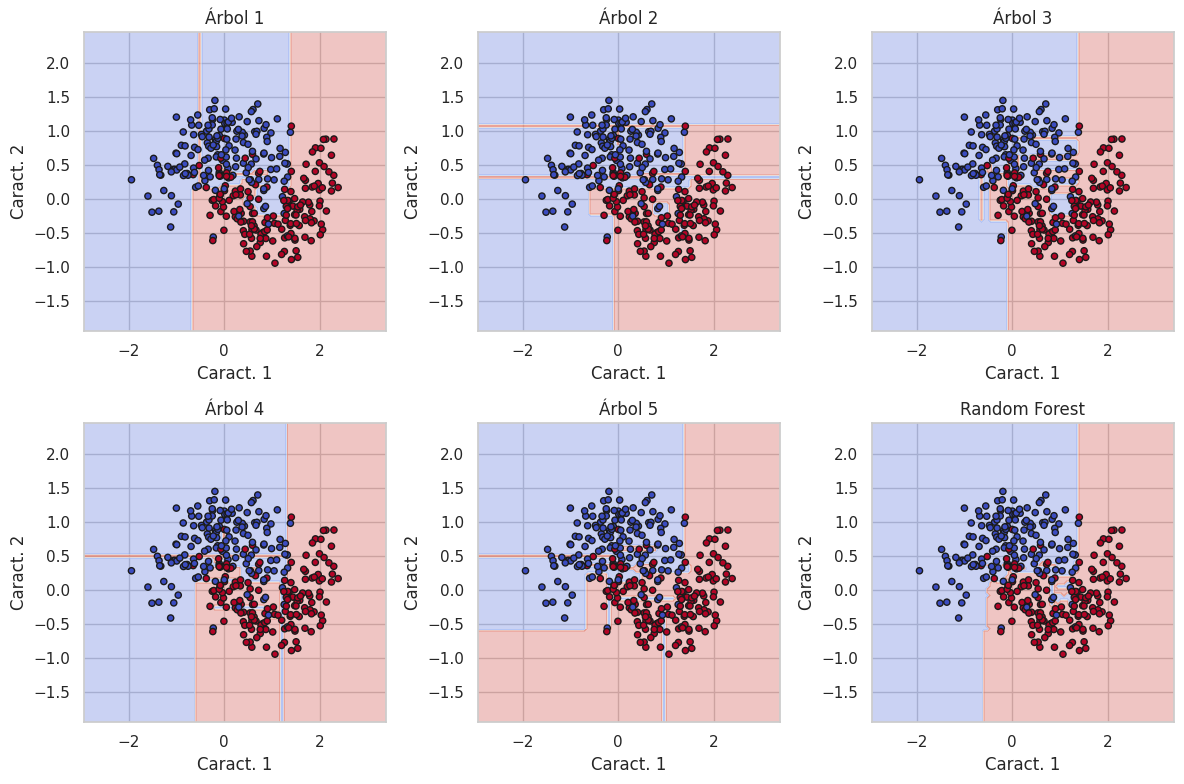

In [ ]:
from sklearn.inspection import DecisionBoundaryDisplay

# Aseguramos la existencia y entrenamiento de rf_clf con Xtrn y ytrn
rf_clf = RandomForestClassifier(n_estimators=200, max_features='sqrt',
                                random_state=SEMILLA)
rf_clf.fit(X_train_moons, y_train_moons)

fig, axes = plt.subplots(2, 3, figsize=(12, 8))
axes_flat = axes.ravel()

# Gráfica de los árboles individuales del bosque
for i, (ax, arb) in enumerate(zip(axes_flat[:-1], rf_clf.estimators_)):
    DecisionBoundaryDisplay.from_estimator(
        arb, X_train_moons, response_method="predict", ax=ax, alpha=0.3,
        cmap=plt.cm.coolwarm)
    ax.scatter(X_train_moons[:, 0], X_train_moons[:, 1], c=y_train_moons,
               edgecolor='k', s=20, cmap=plt.cm.coolwarm)
    ax.set_title(f"Árbol {i+1}")
    ax.set_xlabel("Caract. 1")
    ax.set_ylabel("Caract. 2")

# Gráfica del Random Forest completo en el último subplot
ax_rf = axes_flat[-1]
DecisionBoundaryDisplay.from_estimator(
    rf_clf, X_train_moons, response_method="predict",
    ax=ax_rf, alpha=0.3, cmap=plt.cm.coolwarm
)
scatter = ax_rf.scatter(
    X_train_moons[:, 0], X_train_moons[:, 1], c=y_train_moons,
    edgecolor='k', s=20, cmap=plt.cm.coolwarm)
ax_rf.set_title("Random Forest")
ax_rf.set_xlabel("Caract. 1")
ax_rf.set_ylabel("Caract. 2")

plt.tight_layout()
plt.show()

Random Forest es equivalente a un ensamble de árboles de decisión con el [algoritmo Bagging](https://scikit-learn.org/1.5/modules/generated/sklearn.ensemble.BaggingClassifier.html)

In [ ]:
bag_clf = BaggingClassifier(
    DecisionTreeClassifier(max_features='sqrt', random_state=SEMILLA),
    n_estimators=200,
    bootstrap=True,
    oob_score=True,
    n_jobs=-1,
    random_state=SEMILLA
)
bag_clf.fit(X_train_moons, y_train_moons)

# Calculamos predicciones y métricas.
predicciones_bagging = bag_clf.predict(X_test_moons)

accuracy = accuracy_score(y_test_moons, predicciones_bagging)
precision = precision_score(y_test_moons, predicciones_bagging)
recall = recall_score(y_test_moons, predicciones_bagging)
f1 = f1_score(y_test_moons, predicciones_bagging)

print('Métricas del Algoritmo Bagging:')
print(f'Accuracy:  {accuracy:.3f}')
print(f'Precision: {precision:.3f}')
print(f'Recall:    {recall:.3f}')
print(f'F1 Score:  {f1:.3f}')
print(f'Accuracy OOB: {bag_clf.oob_score_:.3f}')

Métricas del Algoritmo Bagging:
Accuracy:  0.887
Precision: 0.878
Recall:    0.900
F1 Score:  0.889
Accuracy OOB: 0.869


In [ ]:
# Construimos una tabla comparativa.
comparacion_modelos_sinteticos = pd.DataFrame({
    "Modelo": [
        "Árbol profundo",
        "Bagging (base)",
        "Bagging (max_features='sqrt')",
        "Random Forest"
    ],
    "Accuracy de prueba": [
        accuracy_test_arbol,
        accuracy_bagging,
        accuracy_score(y_test_moons, bag_clf.predict(X_test_moons)),
        accuracy_random_forest
    ],
    "F1 de prueba": [
        f1_score(y_test_moons, predicciones_test_arbol),
        f1_bagging,
        f1_score(y_test_moons, bag_clf.predict(X_test_moons)),
        f1_random_forest
    ],
    "Accuracy OOB": [
        np.nan,
        modelo_bagging.oob_score_,
        bag_clf.oob_score_,
        modelo_random_forest.oob_score_
    ]
})

display(
    comparacion_modelos_sinteticos.round(3)
)

,Modelo,Accuracy de prueba,F1 de prueba,Accuracy OOB
0,Árbol profundo,0.875,0.878,NaN
1,Bagging (base),0.888,0.889,0.866
2,Bagging (max_features='sqrt'),0.888,0.889,0.869
3,Random Forest,0.888,0.889,0.884


1. ¿Qué diferencia conceptual existe entre Bagging y Random Forest?
2. ¿Por qué `max_features="sqrt"` puede generar árboles más diversos?

## Optimización de parámetros
* n_estimators: Número de árboles en el bosque. Aumentar este valor
generalmente mejora el rendimiento del modelo, pero también aumenta el costo computacional.

* max_depth: La profundidad máxima de los árboles. Limitar la profundidad ayuda
a prevenir el sobreajuste.

* min_samples_split: El número mínimo de muestras requeridas para dividir un
nodo interno.

* min_samples_leaf: El número mínimo de muestras requeridas para estar en un
nodo hoja.

* max_leaf_nodes: número máximo de nodos terminales

In [ ]:
# Definición de un modelo clasificador de Random Forest
rf_clf = RandomForestClassifier(random_state=SEMILLA)

# Definir los hiperparámetros a ajustar y sus posibles valores
param_grid = {
    'n_estimators': [50, 100, 150],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_leaf_nodes': [3, 5, 7]
}

# Configurar la búsqueda grid con validación cruzada (cross-validation)
grid_search = GridSearchCV(estimator=rf_clf, param_grid=param_grid,
                           cv=5, scoring='accuracy')

# Realizar la búsqueda grid en el conjunto de entrenamiento
grid_search.fit(X_train_moons, y_train_moons)

# Obtener los mejores hiperparámetros encontrados
best_params = grid_search.best_params_
print('Mejores hiperparámetros:', best_params)

# Utilizar el modelo con los mejores hiperparámetros para hacer predicciones
# en el conjunto de prueba
best_rf_classifier = grid_search.best_estimator_
y_pred_GS = best_rf_classifier.predict(X_test_moons)
# Evaluar el rendimiento del modelo con los mejores hiperparámetros
accuracy = accuracy_score(y_test_moons, y_pred_GS)
print(f'Accuracy con mejores hiperparámetros: {accuracy:.2f}')

Mejores hiperparámetros: {'max_depth': None, 'max_leaf_nodes': 7, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 50}
Accuracy con mejores hiperparámetros: 0.86


In [ ]:
# Calculamos individualmente cada métrica
acc_gs = accuracy_score(y_test_moons, y_pred_GS)
prec_gs = precision_score(y_test_moons, y_pred_GS)
rec_gs = recall_score(y_test_moons, y_pred_GS)
f1_gs = f1_score(y_test_moons, y_pred_GS)

print('Métricas de Random Forest (Grid Search):')
print(f'Accuracy:  {acc_gs:.3f}')
print(f'Precision: {prec_gs:.3f}')
print(f'Recall:    {rec_gs:.3f}')
print(f'F1 Score:  {f1_gs:.3f}')

Métricas de Random Forest (Grid Search):
Accuracy:  0.863
Precision: 0.837
Recall:    0.900
F1 Score:  0.867


## Importancia de las características

In [ ]:
from sklearn.datasets import load_iris

iris = load_iris(as_frame=True)
rnd_clf = RandomForestClassifier(n_estimators=500, random_state=SEMILLA)
rnd_clf.fit(iris.data, iris.target)
for score, name in zip(rnd_clf.feature_importances_, iris.data.columns):
    print(round(score, 2), name)

0.1 sepal length (cm)
0.03 sepal width (cm)
0.43 petal length (cm)
0.45 petal width (cm)


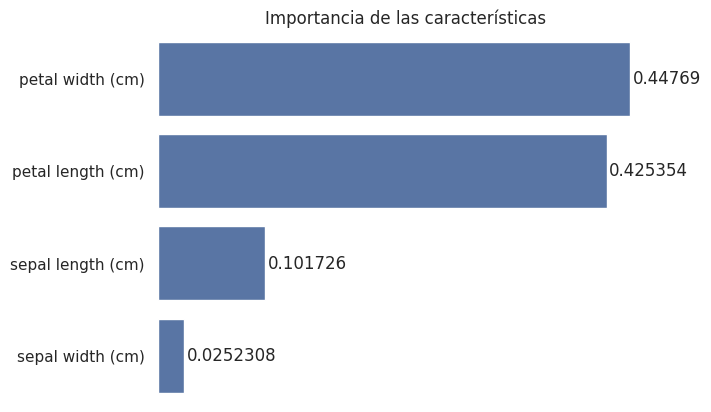

In [ ]:
#Creo un df con dos columnas: características e importancias
features_df = pd.DataFrame({'features': iris.data.columns,
                            'importances': rnd_clf.feature_importances_ })

# Ordeno en base a la importancia
features_df_sorted = features_df.sort_values(by='importances', ascending=False)

g = sns.barplot(data=features_df_sorted, x='importances', y ='features')
sns.despine(bottom = True, left = True)
g.set_title('Importancia de las características')
g.set(xlabel=None, ylabel=None, xticks=[])
for value in g.containers:
    g.bar_label(value, padding=2)

### 📝 Resumen Comparativo de Ensambles

| Método | Muestreo de Datos y Atributos | Agregación | Objetivo Principal |
| :--- | :--- | :--- | :--- |
| **Bagging** | • Bootstrap (con reemplazo)<br>• Todos los atributos ($d$) | Voto mayoritario /<br>Promedio simple | Reducir varianza <br>(mantener bajo sesgo) |
| **Random Forest** | • Bootstrap (con reemplazo)<br>• Subconjunto $m < d$ por nodo | Voto mayoritario /<br>Promedio simple | Descorrelacionar árboles<br>y reducir varianza |
